# Outfit Matcher (small version): identify a garment, generate what goes with it

Upload a photo of one clothing item. An outfit here is **shirt + pants + shoes**: the model identifies what you uploaded and generates the pieces that are missing.

1. **Find the garment.** The photo is cut down to the garment (background removal), so shadows, hangers and walls do not confuse the next steps.
2. **Identify it.** A ResNet18 that we **fine-tune (transfer learning)** on about 9,000 labelled garment photos says what it is (T-shirt, shirt, jeans, shoes, and 11 other types). If it is not sure, it asks you instead of guessing.
3. **Read its colour.** K-means clustering on the garment pixels finds the main colour.
4. **Plan 3 looks.** Simple colour-theory rules choose matching colours for the missing pieces.
5. **Generate the missing pieces.** A pretrained diffusion model (SD-Turbo) draws them in colour for each look. Every image is checked for its planned colour **and** for being the right kind of garment.

```
 photo ──► [crop to garment] ──► [fine-tuned ResNet18] ──► "shirt" ──► colour rules ──► [SD-Turbo] ──► the missing pieces
                                    (we train this)                    (3 looks)        (pretrained)
```

**How to run.** Runtime > Change runtime type > **T4 GPU**. Run the cells one by one (Shift+Enter). Training takes about 3 minutes. Cell 9 needs no photo, cell 10 uploads yours, cell 10b shows what the model saw in your photo (use it if a result looks wrong), cell 11 starts a web page with an upload button.

**What gets generated.** Upload a shirt: you get pants and shoes. Upload pants: shirt and shoes. Upload shoes: shirt and pants. Upload a dress (it covers shirt and pants): shoes.

**Limits.** Colours and pairings come from rules, not from a model trained on real outfits. The model sees 15 garment types only and was trained on small catalogue photos, so one item on a plain background works best. If the model is unsure, set the garment type yourself (`ROLE_OVERRIDE` in cell 10, or the dropdown in cell 11).


In [1]:
# ---------------- CELL 1: Install and check GPU ----------------
!pip install -q diffusers transformers accelerate datasets gradio scikit-learn

import random
import numpy as np
import torch
random.seed(0); np.random.seed(0); torch.manual_seed(0)      # repeatable runs

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
if device == "cpu":
    print("-> Switch to a GPU: Runtime > Change runtime type > T4 GPU, then run again.")

Device: cuda


In [2]:
# ---------------- CELL 2: Colour tools (palette, Lab distance, garment cut-out, garment colour) ----------------
import io, base64, colorsys, time, random

import cv2

import numpy as np
from PIL import Image
from sklearn.cluster import KMeans

# Fashion colour names. They match the catalogue's `baseColour` values where possible.
PALETTE = {
    "Black": (20, 20, 20), "White": (245, 245, 245), "Off White": (238, 232, 215),
    "Cream": (250, 240, 200), "Beige": (222, 205, 175), "Grey": (128, 128, 128),
    "Charcoal": (54, 69, 79), "Navy Blue": (25, 35, 80), "Blue": (45, 100, 200),
    "Teal": (0, 128, 128), "Green": (40, 140, 70), "Olive": (110, 115, 40),
    "Khaki": (170, 160, 100), "Mustard": (205, 160, 30), "Yellow": (240, 220, 50),
    "Orange": (240, 130, 30), "Rust": (170, 75, 35), "Red": (200, 30, 40),
    "Maroon": (110, 20, 35), "Pink": (240, 150, 180), "Purple": (110, 50, 150),
    "Lavender": (190, 170, 225), "Brown": (100, 65, 40), "Tan": (190, 150, 100),
    "Peach": (255, 200, 170),
}
NAMES = list(PALETTE)


def rgb_to_lab(rgb):
    """sRGB (0-255) -> CIE Lab. Works on one colour or an (n,3) array."""
    c = np.asarray(rgb, dtype=np.float64).reshape(-1, 3) / 255.0
    c = np.where(c > 0.04045, ((c + 0.055) / 1.055) ** 2.4, c / 12.92)
    m = np.array([[0.4124, 0.3576, 0.1805], [0.2126, 0.7152, 0.0722], [0.0193, 0.1192, 0.9505]])
    xyz = c @ m.T / np.array([0.95047, 1.0, 1.08883])
    f = np.where(xyz > 0.008856, np.cbrt(xyz), 7.787 * xyz + 16 / 116)
    return np.stack([116 * f[:, 1] - 16, 500 * (f[:, 0] - f[:, 1]), 200 * (f[:, 1] - f[:, 2])], axis=1)


PAL_LAB = rgb_to_lab(np.array([PALETTE[n] for n in NAMES]))


def delta_e(rgb_a, rgb_b):
    return float(np.linalg.norm(rgb_to_lab(rgb_a)[0] - rgb_to_lab(rgb_b)[0]))


def nearest_color_name(rgb, exclude=()):
    d = np.linalg.norm(PAL_LAB - rgb_to_lab(rgb)[0], axis=1)
    for i in np.argsort(d):
        if NAMES[i] not in exclude:
            return NAMES[i]


def _small(img, max_side=256):
    im = img.convert("RGB")
    im.thumbnail((max_side, max_side))
    return np.asarray(im)


def _largest_blob(mask):
    """Close small gaps, then keep only the biggest connected region (drops speckle and stray objects)."""
    m = cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    n, lab, stats, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
    if n <= 1:
        return np.zeros(mask.shape, bool)
    return lab == (1 + np.argmax(stats[1:, cv2.CC_STAT_AREA]))


def _lab(a):
    """uint8 RGB array (h,w,3) -> CIE Lab float array, via OpenCV (L 0-100, a/b about -128..127)."""
    lab = cv2.cvtColor(a.astype(np.float32) / 255.0, cv2.COLOR_RGB2LAB)
    return lab


def segment_garment(a):
    """Boolean mask of the garment in an RGB uint8 array. Returns (mask, method); mask is None if nothing reliable.
    1) Background model: the border pixels are the background. Learn their colour range (shadows, folds, gradients)
       with k-means and call everything far from that range the garment. Used only when the border is consistent.
    2) GrabCut for busy backgrounds / people / hangers, seeded with 'the garment is around the middle'."""
    h, w, _ = a.shape
    lab = _lab(a)
    border = np.concatenate([lab[0], lab[-1], lab[:, 0], lab[:, -1]])
    kb = min(4, len(np.unique(border.round(1), axis=0)))               # a perfectly flat border has 1 colour
    km = KMeans(n_clusters=kb, n_init=3, random_state=0).fit(border)
    d_border = np.linalg.norm(border[:, None, :] - km.cluster_centers_[None], axis=2).min(axis=1)
    if np.percentile(d_border, 90) < 14:                                  # border is a consistent background
        d_all = np.linalg.norm(lab.reshape(-1, 1, 3) - km.cluster_centers_[None], axis=2).min(axis=1).reshape(h, w)
        m = _largest_blob(d_all > 22)
        if 0.02 < m.mean() < 0.92:
            return m, "background model"
    try:
        gc = np.full((h, w), cv2.GC_PR_BGD, np.uint8)
        my, mx = max(1, int(h * .06)), max(1, int(w * .06))
        gc[my:h - my, mx:w - mx] = cv2.GC_PR_FGD                          # probably garment
        gc[int(h * .35):int(h * .65), int(w * .35):int(w * .65)] = cv2.GC_FGD    # surely garment (middle)
        gc[:my], gc[-my:], gc[:, :mx], gc[:, -mx:] = (cv2.GC_BGD,) * 4    # surely background (frame)
        cv2.grabCut(np.ascontiguousarray(a[:, :, ::-1]), gc, None,
                    np.zeros((1, 65)), np.zeros((1, 65)), 4, cv2.GC_INIT_WITH_MASK)
        m = _largest_blob((gc == cv2.GC_FGD) | (gc == cv2.GC_PR_FGD))
        if 0.05 < m.mean() < 0.85:
            return m, "grabcut"
    except cv2.error:
        pass
    return None, "centre crop"


def garment_pixels(img, max_side=256):
    """(RGB pixels of the garment, method used). Falls back to the middle of the picture."""
    a = _small(img, max_side)
    mask, how = segment_garment(a)
    if mask is not None:
        return a[mask].astype(np.float64), how
    h, w, _ = a.shape
    return a[int(h * .3):int(h * .7), int(w * .3):int(w * .7)].reshape(-1, 3).astype(np.float64), how


def crop_garment(img, max_side=384, margin=0.06):
    """Crop the photo to the garment so the classifier sees an item, not a whole scene."""
    im = img.convert("RGB")
    im.thumbnail((max_side, max_side))
    a = np.asarray(im)
    mask, _ = segment_garment(a)
    if mask is None:
        return im
    ys, xs = np.where(mask)
    h, w = mask.shape
    py, px = int((ys.max() - ys.min()) * margin) + 2, int((xs.max() - xs.min()) * margin) + 2
    return im.crop((max(0, xs.min() - px), max(0, ys.min() - py), min(w, xs.max() + px + 1), min(h, ys.max() + py + 1)))


def dominant_color(img, k=3, seed=0):
    """Main colour of the garment (largest k-means cluster of its pixels), as an RGB tuple.
    If the segmentation was only approximate (GrabCut / centre crop) and the biggest cluster is a dull white/grey
    (probably leftover background), a clearly coloured cluster of similar size wins instead."""
    px, how = garment_pixels(img)
    if len(px) > 6000:
        px = px[np.random.default_rng(seed).choice(len(px), 6000, replace=False)]
    k = min(k, len(np.unique(px.astype(int), axis=0)))
    if k <= 1:
        return tuple(int(v) for v in px.mean(axis=0))
    km = KMeans(n_clusters=k, n_init=3, random_state=seed).fit(px)
    sizes = np.bincount(km.labels_, minlength=k)
    best = int(sizes.argmax())
    if how != "background model":
        lab = _lab(km.cluster_centers_.reshape(1, -1, 3).astype(np.uint8))[0]
        chroma = np.linalg.norm(lab[:, 1:], axis=1)
        if chroma[best] < 12 and lab[best, 0] > 60:
            lively = [i for i in range(k) if chroma[i] > 30 and sizes[i] >= 0.5 * sizes[best]]
            if lively:
                best = max(lively, key=lambda i: sizes[i])
    return tuple(int(v) for v in km.cluster_centers_[best])


def pil_to_b64(img, size=220):
    im = img.convert("RGB")
    im.thumbnail((size, size))
    buf = io.BytesIO()
    im.save(buf, format="JPEG", quality=88)
    return base64.b64encode(buf.getvalue()).decode()

In [3]:
# ---------------- CELL 3: Outfit planner (colour-theory rules) ----------------
# For a neutral piece we use stylist pairings. For a coloured piece we use colour harmony:
#   Look 1 = safe neutral, Look 2 = analogous (neighbouring hue, muted), Look 3 = complementary (opposite hue, muted).
NEUTRAL_PAIRS = {
    "White": ["Navy Blue", "Black", "Khaki"],       "Off White": ["Navy Blue", "Black", "Olive"],
    "Cream": ["Navy Blue", "Brown", "Olive"],       "Beige": ["Navy Blue", "Olive", "Brown"],
    "Black": ["Blue", "Grey", "Beige"],             "Grey": ["Navy Blue", "Black", "Maroon"],
    "Charcoal": ["Blue", "Beige", "Khaki"],         "Navy Blue": ["Beige", "Grey", "White"],
    "Brown": ["Beige", "Navy Blue", "Cream"],       "Tan": ["Navy Blue", "White", "Olive"],
    "Khaki": ["Navy Blue", "Black", "White"],
}
NEUTRAL_RULES = ["Classic neutral pairing", "Tone contrast", "Earthy accent"]
VIVID = {"Purple", "Pink", "Yellow", "Orange", "Lavender", "Peach", "Red"}   # too loud as a derived partner colour
EARTHY = {"Khaki", "Olive", "Beige", "Brown", "Tan", "Cream", "Rust", "Mustard"}
DARK_COOL = {"Navy Blue", "Blue", "Black", "Charcoal", "Grey", "Teal"}


def _hue_color(h, s, l, exclude):
    return nearest_color_name(tuple(255 * v for v in colorsys.hls_to_rgb(h % 1.0, l, s)), exclude=set(exclude) | VIVID)


def harmony_colors(base_rgb):
    """Three (colour name, rule) suggestions that go with base_rgb."""
    base = nearest_color_name(base_rgb)
    if base in NEUTRAL_PAIRS:
        return list(zip(NEUTRAL_PAIRS[base], NEUTRAL_RULES))
    h, l, s = colorsys.rgb_to_hls(*[v / 255 for v in base_rgb])
    used = {base}
    safe = "Beige" if (0.55 < h < 0.75) else "Navy Blue"          # blues pair better with beige than with navy
    if safe in used:
        safe = "Grey"
    used.add(safe)
    analog = _hue_color(h + 0.08, min(s, 0.45), 0.35, used)          # neighbouring hue, muted and darker
    used.add(analog)
    comp = _hue_color(h + 0.5, 0.40, 0.36, used)                     # opposite hue, muted
    if comp in used:
        comp = next(c for c in ["Black", "White", "Grey", "Khaki"] if c not in used)
    return [(safe, "Classic neutral pairing"), (analog, "Tone-on-tone (analogous)"), (comp, "Contrast (complementary)")]


def shoe_color(bottom_name, i):
    if bottom_name in EARTHY:
        order = ["White", "Brown", "Black"]
    elif bottom_name in DARK_COOL:
        order = ["White", "Black", "Brown"]
    else:
        order = ["White", "Black", "Beige"]
    choice = order[i % 3]
    return choice if choice != bottom_name else order[(i + 1) % 3]


# What to generate for each missing role: (noun used in the prompt, catalogue articleTypes to search).
ITEM_OPTIONS = {
    ("top", "Men", "casual"):       [("t-shirt", ["Tshirts"]), ("casual shirt", ["Shirts"]), ("sweatshirt", ["Sweatshirts"])],
    ("top", "Men", "formal"):       [("formal shirt", ["Shirts"])],
    ("top", "Women", "casual"):     [("top", ["Tops"]), ("t-shirt", ["Tshirts"]), ("casual shirt", ["Shirts"])],
    ("top", "Women", "formal"):     [("formal shirt", ["Shirts"]), ("blouse top", ["Tops"])],
    ("bottom", "Men", "casual"):    [("jeans", ["Jeans"]), ("chino trousers", ["Trousers"]), ("tapered trousers", ["Trousers"])],
    ("bottom", "Men", "formal"):    [("formal trousers", ["Trousers"])],
    ("bottom", "Women", "casual"):  [("jeans", ["Jeans"]), ("trousers", ["Trousers"]), ("skirt", ["Skirts"])],
    ("bottom", "Women", "formal"):  [("formal trousers", ["Trousers"]), ("pencil skirt", ["Skirts"])],
    ("shoes", "Men", "casual"):     [("sneakers", ["Casual Shoes", "Sports Shoes"]), ("canvas casual shoes", ["Casual Shoes"]), ("loafers", ["Casual Shoes"])],
    ("shoes", "Men", "formal"):     [("leather formal shoes", ["Formal Shoes"])],
    ("shoes", "Women", "casual"):   [("sneakers", ["Casual Shoes", "Sports Shoes"]), ("flats", ["Flats"]), ("sandals", ["Sandals"])],
    ("shoes", "Women", "formal"):   [("block heels", ["Heels"]), ("formal flats", ["Flats"]), ("pumps", ["Heels", "Formal Shoes"])],
}
NEEDS = {"top": ["bottom", "shoes"], "bottom": ["top", "shoes"], "dress": ["shoes"], "shoes": ["top", "bottom"]}


def plan_outfit(role, base_rgb, gender="Men", style="casual"):
    """Returns the three planned looks. Each look lists the items to generate."""
    base_name = nearest_color_name(base_rgb)
    picks = harmony_colors(base_rgb)
    looks = []
    for i, (pick, rule) in enumerate(picks):
        colors = {}
        if role == "top":
            colors["bottom"] = pick
            colors["shoes"] = shoe_color(pick, i)
        elif role == "bottom":
            colors["top"] = pick
            colors["shoes"] = shoe_color(base_name, i)
        elif role == "dress":
            colors["shoes"] = shoe_color(base_name, i) if i < 2 else "Black"
        else:  # shoes uploaded
            colors["bottom"] = pick
            partner = next(c for c, _ in harmony_colors(PALETTE[pick]) if c not in (pick, base_name))
            colors["top"] = partner
        items = []
        for need in NEEDS[role]:
            options = ITEM_OPTIONS[(need, gender, style)]
            noun, types = options[i % len(options)]
            items.append({"role": need, "color": colors[need], "noun": noun, "types": types})
        looks.append({"title": f"Look {i + 1}: {rule}", "rule": rule, "items": items})
    return {"base_name": base_name, "role": role, "looks": looks}

In [4]:
# ---------------- CELL 4: Training data (real garment photos with labels) ----------------
import numpy as np, pandas as pd
from datasets import load_dataset
from sklearn.model_selection import train_test_split

# The garment types the model will learn, and what each one is for outfit planning.
CLASS_ROLE = {
    "Tshirts": "top", "Shirts": "top", "Tops": "top", "Sweatshirts": "top", "Jackets": "top",
    "Jeans": "bottom", "Trousers": "bottom", "Shorts": "bottom", "Skirts": "bottom",
    "Dresses": "dress",
    "Casual Shoes": "shoes", "Formal Shoes": "shoes", "Sports Shoes": "shoes", "Sandals": "shoes", "Heels": "shoes",
}
PER_CLASS = 800                                   # cap per class so T-shirts do not dominate

full = load_dataset("ashraq/fashion-product-images-small", split="train")
meta = full.remove_columns("image").to_pandas()   # labels only, images stay undecoded
meta = meta[meta["articleType"].isin(CLASS_ROLE)]
CLASSES = [c for c in CLASS_ROLE if c in set(meta["articleType"])]
sel = meta.sample(frac=1, random_state=0).groupby("articleType").head(PER_CLASS)
print(sel["articleType"].value_counts().to_string())

images = [im.convert("RGB") for im in full.select(sel.index.to_list())["image"]]
labels = np.array([CLASSES.index(a) for a in sel["articleType"]])

# 70% train, 15% validation (used to pick the best epoch), 15% test (touched once, for the final score)
idx_train, idx_tmp = train_test_split(np.arange(len(labels)), test_size=0.30, stratify=labels, random_state=0)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, stratify=labels[idx_tmp], random_state=0)
print(f"\n{len(CLASSES)} classes | train {len(idx_train)} | validation {len(idx_val)} | test {len(idx_test)}")

README.md:   0%|          | 0.00/867 [00:00<?, ?B/s]

data/train-00000-of-00002-6cff4c59f91661(…): reconstructing file:   0%|          |  0.00B /  136MB            

data/train-00000-of-00002-6cff4c59f91661(…): downloading bytes:           |  0.00B            

data/train-00001-of-00002-bb459e5ac5f01e(…): reconstructing file:   0%|          |  0.00B /  135MB            

data/train-00001-of-00002-bb459e5ac5f01e(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/44072 [00:00<?, ? examples/s]

articleType
Tshirts         800
Casual Shoes    800
Shirts          800
Sports Shoes    800
Sandals         800
Heels           800
Tops            800
Formal Shoes    637
Jeans           602
Shorts          547
Trousers        530
Dresses         464
Sweatshirts     285
Jackets         258
Skirts          128

15 classes | train 6335 | validation 1358 | test 1358


In [5]:
# ---------------- CELL 5: Transfer learning - fine-tune a pretrained ResNet18 ----------------
import copy
import torch.nn as nn
from torchvision import models, transforms as T
from PIL import Image

IMG_H, IMG_W = 128, 96                            # catalogue photos are portrait 3:4
CATALOGUE_SIZE = (60, 80)                         # (width, height) of the real training photos


def to_portrait(img):
    """Pad (never stretch) to 3:4 portrait using the photo's own background colour."""
    img = img.convert("RGB")
    w, h = img.size
    if abs(w / h - 0.75) < 0.05:
        return img
    a = np.asarray(img)
    bg = tuple(int(v) for v in np.median(np.concatenate([a[0], a[-1], a[:, 0], a[:, -1]]), axis=0))
    nw, nh = (w, int(round(w / 0.75))) if w / h > 0.75 else (int(round(h * 0.75)), h)
    canvas = Image.new("RGB", (nw, nh), bg)
    canvas.paste(img, ((nw - w) // 2, (nh - h) // 2))
    return canvas


def prepare_for_model(img):
    """Make a real-world photo look like the training photos before the network sees it:
    cut it down to the garment, pad to portrait, and shrink to catalogue size (tiny and soft, like the training data).
    Catalogue photos pass through almost unchanged."""
    img = to_portrait(crop_garment(img))
    return img.resize(CATALOGUE_SIZE, Image.LANCZOS)


norm = T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])        # ImageNet statistics
# Augmentation: crops, small shifts/zoom-out (garment not perfectly centred), blur, flips, colour changes.
train_tf = T.Compose([T.RandomResizedCrop((IMG_H, IMG_W), scale=(0.75, 1.0), ratio=(0.7, 0.85)),
                      T.RandomAffine(degrees=8, translate=(0.08, 0.08), scale=(0.8, 1.1), fill=(240, 240, 240)),
                      T.RandomApply([T.GaussianBlur(3, (0.1, 1.2))], p=0.3),
                      T.RandomHorizontalFlip(), T.ColorJitter(0.3, 0.2, 0.4, 0.05), T.ToTensor(), norm])
eval_tf = T.Compose([T.Resize((IMG_H, IMG_W)), T.ToTensor(), norm])


class GarmentSet(torch.utils.data.Dataset):
    def __init__(self, idx, tf):
        self.idx, self.tf = idx, tf
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        return self.tf(to_portrait(images[j])), int(labels[j])


train_dl = torch.utils.data.DataLoader(GarmentSet(idx_train, train_tf), batch_size=64, shuffle=True, num_workers=2)
val_dl = torch.utils.data.DataLoader(GarmentSet(idx_val, eval_tf), batch_size=128, num_workers=2)
test_dl = torch.utils.data.DataLoader(GarmentSet(idx_test, eval_tf), batch_size=128, num_workers=2)

# Pretrained on ImageNet (1.2M photos). We only replace the last layer with one for our garment classes.
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
model.fc = nn.Linear(model.fc.in_features, len(CLASSES))
model = model.to(device)

counts = np.bincount(labels[idx_train], minlength=len(CLASSES))
loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(counts.sum() / (len(counts) * counts), dtype=torch.float32).to(device))
history = []
best = {"acc": 0.0, "state": None, "epoch": 0}


def evaluate(dl):
    model.eval()
    preds, targets, total = [], [], 0.0
    with torch.no_grad():
        for x, y in dl:
            out = model(x.to(device))
            total += loss_fn(out, y.to(device)).item() * len(y)
            preds += out.argmax(1).cpu().tolist()
            targets += y.tolist()
    return total / len(targets), float(np.mean(np.array(preds) == np.array(targets))), preds, targets


def run_epochs(epochs, params, lr, phase):
    opt = torch.optim.Adam(params, lr=lr)
    for ep in range(epochs):
        model.train()
        for m in model.modules():                 # keep the pretrained batch-norm statistics fixed
            if isinstance(m, nn.BatchNorm2d):
                m.eval()
        tl, n = 0.0, 0
        for x, y in train_dl:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            loss = loss_fn(model(x), y)
            loss.backward()
            opt.step()
            tl += loss.item() * len(y)
            n += len(y)
        vl, va, _, _ = evaluate(val_dl)
        history.append({"phase": phase, "train_loss": tl / n, "val_loss": vl, "val_acc": va})
        star = ""
        if va > best["acc"]:                      # remember the best epoch, not just the last one
            best.update(acc=va, state=copy.deepcopy(model.state_dict()), epoch=len(history))
            star = "  <- best so far"
        print(f"[{phase}] epoch {ep + 1}/{epochs}  train loss {tl / n:.3f}  val loss {vl:.3f}  val accuracy {va:.1%}{star}")


# Phase 1: freeze the whole backbone, train only the new final layer.
for p in model.parameters():
    p.requires_grad = False
for p in model.fc.parameters():
    p.requires_grad = True
run_epochs(3, model.fc.parameters(), 1e-3, "head only")

# Phase 2: also unfreeze the last block (layer4) and fine-tune gently.
for p in model.layer4.parameters():
    p.requires_grad = True
run_epochs(4, list(model.layer4.parameters()) + list(model.fc.parameters()), 1e-4, "fine-tune")

model.load_state_dict(best["state"])              # go back to the best epoch
print(f"\nKept the best epoch: {best['epoch']} of {len(history)} (validation accuracy {best['acc']:.1%})")
torch.save({"state_dict": model.state_dict(), "classes": CLASSES}, "garment_classifier.pt")
print("Saved garment_classifier.pt")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 212MB/s]


[head only] epoch 1/3  train loss 1.555  val loss 1.123  val accuracy 61.9%  <- best so far
[head only] epoch 2/3  train loss 1.024  val loss 0.952  val accuracy 67.8%  <- best so far
[head only] epoch 3/3  train loss 0.892  val loss 0.885  val accuracy 70.5%  <- best so far
[fine-tune] epoch 1/4  train loss 0.821  val loss 0.641  val accuracy 75.8%  <- best so far
[fine-tune] epoch 2/4  train loss 0.608  val loss 0.607  val accuracy 78.6%  <- best so far
[fine-tune] epoch 3/4  train loss 0.518  val loss 0.489  val accuracy 81.5%  <- best so far
[fine-tune] epoch 4/4  train loss 0.469  val loss 0.450  val accuracy 82.5%  <- best so far

Kept the best epoch: 7 of 7 (validation accuracy 82.5%)
Saved garment_classifier.pt


Test accuracy, 15 garment types : 81.2%
Test accuracy, role (top / bottom / dress / shoes): 98.5%   <- this is what the outfit planner uses

              precision    recall  f1-score   support

     Tshirts       0.77      0.82      0.80       120
      Shirts       0.89      0.90      0.90       120
        Tops       0.78      0.62      0.69       120
 Sweatshirts       0.51      0.70      0.59        43
     Jackets       0.64      0.59      0.61        39
       Jeans       0.96      0.79      0.87        91
    Trousers       0.84      0.96      0.90        80
      Shorts       0.95      0.93      0.94        82
      Skirts       0.77      0.89      0.83        19
     Dresses       0.84      0.88      0.86        69
Casual Shoes       0.71      0.62      0.66       120
Formal Shoes       0.89      0.96      0.92        95
Sports Shoes       0.73      0.87      0.79       120
     Sandals       0.85      0.85      0.85       120
       Heels       0.89      0.78      0.83     

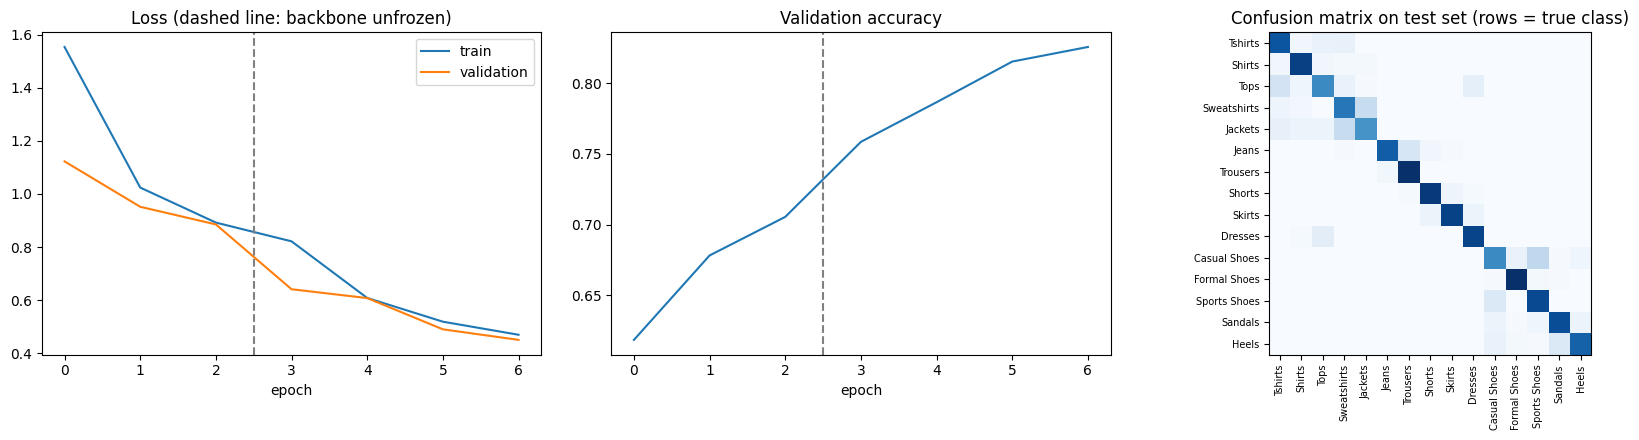

In [6]:
# ---------------- CELL 6: Results - test accuracy, curves, confusion matrix ----------------
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

# Final score on the TEST set (never used to choose the epoch).
tl_, ta, preds, targets = evaluate(test_dl)
ROLE_OF = np.array([CLASS_ROLE[c] for c in CLASSES])
role_acc = float(np.mean(ROLE_OF[preds] == ROLE_OF[targets]))
print(f"Test accuracy, 15 garment types : {ta:.1%}")
print(f"Test accuracy, role (top / bottom / dress / shoes): {role_acc:.1%}   <- this is what the outfit planner uses\n")
print(classification_report(targets, preds, target_names=CLASSES, digits=2))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].plot([h["train_loss"] for h in history], label="train"); ax[0].plot([h["val_loss"] for h in history], label="validation")
ax[0].axvline(2.5, color="grey", ls="--"); ax[0].set_title("Loss (dashed line: backbone unfrozen)"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot([h["val_acc"] for h in history]); ax[1].axvline(2.5, color="grey", ls="--"); ax[1].set_title("Validation accuracy"); ax[1].set_xlabel("epoch")
cm = confusion_matrix(targets, preds, normalize="true")
ax[2].imshow(cm, cmap="Blues"); ax[2].set_xticks(range(len(CLASSES))); ax[2].set_yticks(range(len(CLASSES)))
ax[2].set_xticklabels(CLASSES, rotation=90, fontsize=7); ax[2].set_yticklabels(CLASSES, fontsize=7); ax[2].set_title("Confusion matrix on test set (rows = true class)")
plt.tight_layout(); plt.show()


@torch.no_grad()
def classify(img, top_k=3):
    """Garment type of any photo. Returns (label, role, confidence, top_k list)."""
    model.eval()
    x = eval_tf(prepare_for_model(img)).unsqueeze(0).to(device)
    p = torch.softmax(model(x), dim=1)[0].cpu().numpy()
    top = [(CLASSES[i], float(p[i])) for i in np.argsort(-p)[:top_k]]
    return top[0][0], CLASS_ROLE[top[0][0]], top[0][1], top

In [7]:
# ---------------- CELL 7: Generate coloured product images (SD-Turbo) with a colour and a type check ----------------
from diffusers import AutoPipelineForText2Image

_dtype = torch.float16 if device == "cuda" else torch.float32
try:
    pipe = AutoPipelineForText2Image.from_pretrained("stabilityai/sd-turbo", torch_dtype=_dtype, variant="fp16" if device == "cuda" else None)
except Exception as e:                                       # some versions have no fp16 variant file
    print("fp16 variant not available, loading default weights:", type(e).__name__)
    pipe = AutoPipelineForText2Image.from_pretrained("stabilityai/sd-turbo", torch_dtype=_dtype)
pipe = pipe.to(device)
pipe.set_progress_bar_config(disable=True)

COLOR_TOLERANCE = 25      # max colour difference (Lab delta-E) between the planned colour and the generated one
TYPE_PENALTY = 25         # added to the colour error when our own classifier says the image is the wrong kind of garment


def make_prompt(color, noun, gender):
    who = "men's" if gender == "Men" else "women's"
    return (f"studio product photo of {who} {color.lower()} {noun}, isolated on a plain light grey background, "
            f"e-commerce catalogue photo, centered, sharp, high detail")


def generate_item(color, noun, gender, role, tries=4, seed=None):
    """Generate an image of `color noun`. Each try is checked twice: is the colour right, and does our classifier
    agree it is a `role` (top / bottom / shoes)? Keep the best try. Returns (image, colour error, type ok)."""
    seed = random.randrange(10_000) if seed is None else seed
    target = PALETTE[color]
    best = None
    for t in range(tries):
        g = torch.Generator(device=device).manual_seed(seed + t)
        img = pipe(prompt=make_prompt(color, noun, gender), num_inference_steps=2,
                   guidance_scale=0.0, height=512, width=512, generator=g).images[0]
        de = delta_e(dominant_color(img), target)
        type_ok = classify(img)[1] == role
        score = de + (0 if type_ok else TYPE_PENALTY)
        if best is None or score < best[0]:
            best = (score, img, de, type_ok)
        if de <= COLOR_TOLERANCE and type_ok:
            break
    return best[1], best[2], best[3]

[transformers] `Siglip2ImageProcessorFast` is deprecated. The `Fast` suffix for image processors has been removed; use `Siglip2ImageProcessor` instead.
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


In [8]:
# ---------------- CELL 8: The whole pipeline: identify -> plan -> generate ----------------
FRIENDLY = {"Tshirts": "T-shirt", "Shirts": "shirt", "Tops": "top", "Sweatshirts": "sweatshirt", "Jackets": "jacket",
            "Jeans": "jeans", "Trousers": "trousers", "Shorts": "shorts", "Skirts": "skirt", "Dresses": "dress",
            "Casual Shoes": "casual shoes", "Formal Shoes": "formal shoes", "Sports Shoes": "sports shoes",
            "Sandals": "sandals", "Heels": "heels"}
CONF_MIN = 0.55            # below this the model says "not sure" instead of guessing
ROLES = ["auto", "top", "bottom", "dress", "shoes"]


def swatch(rgb):
    return f'<span style="display:inline-block;width:14px;height:14px;border-radius:50%;background:rgb{tuple(rgb)};border:1px solid #888;vertical-align:-2px"></span>'


CSS = ("<style>.om{font-family:system-ui,sans-serif;color:#161a33}.om .top{display:flex;gap:16px;align-items:center}"
       ".om .top img{height:150px;border:1px solid #cdd2de}.om .look{border:1px solid #cdd2de;border-radius:8px;padding:6px 16px 14px;margin:14px 0;background:#fbfbfd}"
       ".om .row{display:flex;flex-wrap:wrap;gap:24px}.om .item{width:250px}"
       ".om .gen{width:250px;height:250px;object-fit:contain;border:1px solid #cdd2de;background:#fff}"
       ".om .warn{border:1px solid #e0b040;background:#fff8e6;border-radius:8px;padding:8px 14px;margin-top:10px}"
       ".om small{color:#4a5070}</style>")


def _guesses(top):
    return ", ".join(f"{FRIENDLY[n]} {p:.0%}" for n, p in top)


def render_html(res, upload):
    if res.get("uncertain"):
        ident = (f'<b>Not sure what this is.</b> Best guesses: {_guesses(res["top"])}<br>'
                 f'Colour: {swatch(res["base_rgb"])} <b>{res["base_name"]}</b>')
    elif res["label"] is None:
        ident = (f'<b>Garment type set by you: {res["role"]}</b><br>'
                 f'Colour: {swatch(res["base_rgb"])} <b>{res["base_name"]}</b>')
    else:
        ident = (f'<b>Identified: {FRIENDLY[res["label"]]}</b> ({res["confidence"]:.0%} sure)<br>'
                 f'<small>Top guesses: {_guesses(res["top"])}</small><br>'
                 f'Colour: {swatch(res["base_rgb"])} <b>{res["base_name"]}</b>')
    h = [CSS, '<div class="om">', '<div class="top">',
         f'<img src="data:image/jpeg;base64,{pil_to_b64(upload, 300)}">', f'<div>{ident}</div></div>']
    if res.get("uncertain"):
        h.append('<div class="warn">The model is not confident enough to plan an outfit. '
                 'Tell it what the item is: set <code>ROLE_OVERRIDE</code> to <code>"top"</code>, <code>"bottom"</code>, '
                 '<code>"dress"</code> or <code>"shoes"</code> (cell 10), or use the dropdown in the web page, and run again. '
                 'A photo of just the item on a plain background also helps.</div>')
    for look in res["looks"]:
        h.append(f'<div class="look"><h3>{look["title"]}</h3><div class="row">')
        for it in look["items"]:
            check = "type ok" if it["type_ok"] else "type unsure"
            h.append(f'<div class="item"><img class="gen" src="data:image/jpeg;base64,{pil_to_b64(it["image"], 500)}">'
                     f'<div><b>{swatch(PALETTE[it["color"]])} {it["color"]} {it["noun"]}</b><br>'
                     f'<small>generated, colour error {it["delta_e"]:.0f}, {check}</small></div></div>')
        h.append('</div></div>')
    h.append('</div>')
    return "".join(h)


def recommend(image, gender="Men", style="casual", seed=None, role_override="auto"):
    """Identify the uploaded garment, then generate whichever of shirt, pants and shoes is missing.
    role_override: "auto" trusts the model; "top" / "bottom" / "dress" / "shoes" skips identification."""
    img = (Image.open(image) if isinstance(image, str) else image).convert("RGB")
    label, role, conf, top = classify(img)
    base_rgb = dominant_color(img)
    base_name = nearest_color_name(base_rgb)
    res = {"label": label, "role": role, "confidence": conf, "top": top, "base_rgb": base_rgb,
           "base_name": base_name, "gender": gender, "style": style, "looks": [], "uncertain": False}
    if role_override in ROLES[1:]:
        res.update(label=None, role=role_override)           # the person told us what it is
    elif conf < CONF_MIN:
        res["uncertain"] = True
        res["summary"] = (f"Not sure what this is (best guess {FRIENDLY[label]}, {conf:.0%}). "
                          f"Colour {base_name}. Choose the garment type and run again.")
        res["html"] = render_html(res, img)
        return res
    plan = plan_outfit(res["role"], base_rgb, gender, style)
    t0 = time.time()
    for look in plan["looks"]:
        for it in look["items"]:
            it["image"], it["delta_e"], it["type_ok"] = generate_item(it["color"], it["noun"], gender, it["role"], seed=seed)
    res["looks"] = plan["looks"]
    who = f"{FRIENDLY[label]} ({conf:.0%})" if res["label"] else f"{res['role']} (set by you)"
    res["html"] = render_html(res, img)
    res["summary"] = (f"Identified {who}, colour {base_name}. "
                      f"Generated {sum(len(l['items']) for l in plan['looks'])} items in {time.time() - t0:.0f}s.")
    return res

## Try it
Cell 9 needs no photo. Cell 10 uploads your own, and cell 10b shows what the model saw in it. Cell 11 starts a web page with an upload button.

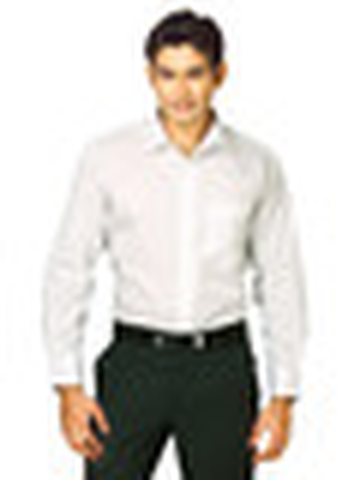

Not sure what this is (best guess jacket, 52%). Colour Peach. Choose the garment type and run again.



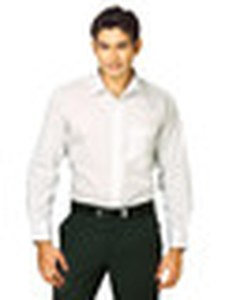

In [9]:
# ---------------- CELL 9: Try it (no upload needed) ----------------
# A shirt the model never trained on (from the validation set), enlarged like a normal photo.
# Expect pants and shoes back, because those are the missing pieces.
from IPython.display import HTML, display

shirt_class = CLASSES.index("Shirts")
test_i = next(i for i in idx_val if labels[i] == shirt_class)
sample_img = images[test_i].resize((360, 480), Image.LANCZOS)
display(sample_img)

result = recommend(sample_img, gender="Men", style="casual", seed=7)
print(result["summary"])
display(HTML(result["html"]))

Saving red shirt.jpg to red shirt.jpg
Not sure what this is (best guess T-shirt, 48%). Colour Red. Choose the garment type and run again.



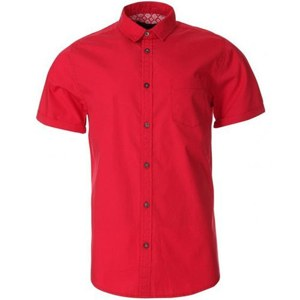

In [10]:
# ---------------- CELL 10: Upload your own photo ----------------
from google.colab import files

uploaded = files.upload()                      # one clothing item, plain background works best
path = next(iter(uploaded))
GENDER = "Men"                                 # "Men" or "Women"
STYLE = "casual"                               # "casual" or "formal"
ROLE_OVERRIDE = "auto"                         # "auto", or tell the model what it is: "top", "bottom", "dress", "shoes"

my_img = Image.open(path).convert("RGB")
result = recommend(my_img, gender=GENDER, style=STYLE, role_override=ROLE_OVERRIDE)
print(result["summary"])
display(HTML(result["html"]))

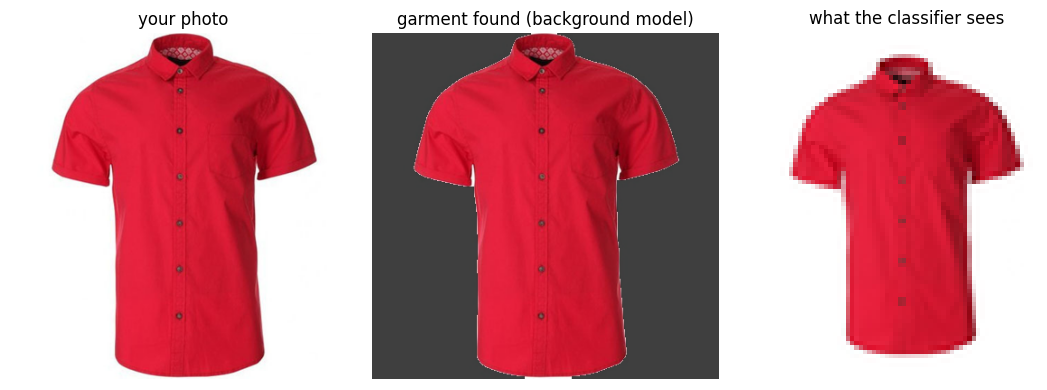

Classifier guesses: T-shirt 48%, shirt 31%, jacket 20%
Colour read from the garment: Red (215, 29, 54)


In [11]:
# ---------------- CELL 10b: What did the model see in my photo? (use when a result looks wrong) ----------------
# Shows the cut-out used for the colour and the crop given to the classifier, plus the classifier's guesses.
import matplotlib.pyplot as plt

a = _small(my_img, 384)
mask, how = segment_garment(a)
overlay = a.copy()
if mask is not None:
    overlay[~mask] = (overlay[~mask] * 0.25).astype(np.uint8)          # darken everything that is NOT garment
label, role, conf, top = classify(my_img)
rgb = dominant_color(my_img)

fig, ax = plt.subplots(1, 3, figsize=(11, 4))
ax[0].imshow(a); ax[0].set_title("your photo")
ax[1].imshow(overlay); ax[1].set_title(f"garment found ({how})")
ax[2].imshow(prepare_for_model(my_img)); ax[2].set_title("what the classifier sees")
for x in ax: x.axis("off")
plt.tight_layout(); plt.show()
print("Classifier guesses:", ", ".join(f"{FRIENDLY[n]} {p:.0%}" for n, p in top))
print("Colour read from the garment:", nearest_color_name(rgb), rgb)
if mask is None or how == "centre crop":
    print("-> No garment outline was found, so the middle of the photo was used. Try a photo with the item filling the frame.")

In [ ]:
# ---------------- CELL 11 (optional): Web page with an upload button ----------------
import gradio as gr

SHARE = False        # True makes a public link anyone can use for about a week (it runs on YOUR GPU, with the safety checker off)


def run_demo(photo, gender, style, role):
    if photo is None:
        return "Upload a photo of one clothing item first.", ""
    res = recommend(photo, gender=gender, style=style, role_override=role)
    return res["summary"], res["html"]


with gr.Blocks(title="Outfit Matcher") as demo:
    gr.Markdown("## Outfit Matcher\nUpload one clothing item. The model identifies it and generates the missing pieces of shirt, pants and shoes.")
    with gr.Row():
        with gr.Column(scale=1):
            photo = gr.Image(type="pil", label="Photo of one clothing item")
            gender = gr.Radio(["Men", "Women"], value="Men", label="Outfit for")
            style = gr.Radio(["casual", "formal"], value="casual", label="Style")
            role = gr.Dropdown(ROLES, value="auto", label="Garment type (leave on auto unless the model is unsure or wrong)")
            go = gr.Button("Match my outfit", variant="primary")
        with gr.Column(scale=3):
            summary = gr.Markdown()
            page = gr.HTML()
    go.click(run_demo, [photo, gender, style, role], [summary, page])

demo.launch(share=SHARE, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

## Notes for your report and viva

**Deep learning concepts used**
- **Convolutional neural network (CNN):** ResNet18, with residual (skip) connections.
- **Transfer learning:** the network is pretrained on ImageNet (1.2 million photos). It already knows edges, textures and shapes, so we reuse it instead of training from scratch.
- **Fine-tuning in two phases:** first only the new last layer is trained (backbone frozen), then the last convolutional block is unfrozen and trained with a smaller learning rate (1e-4). This avoids destroying the pretrained features. The best epoch (by validation accuracy) is kept, not the last one.
- **Data augmentation:** random crop, shift and zoom-out, blur, horizontal flip and colour jitter make the model robust to different photos and colours.
- **Class-weighted cross-entropy loss:** gives rarer garment types more weight so the model does not just favour T-shirts.
- **Evaluation:** train / validation / test split. The validation set picks the best epoch, and the test set is used once for the final score. Reported as accuracy for the 15 garment types and for the 4 roles the planner uses, with per-class precision and recall and a confusion matrix (cell 6).
- **Diffusion model (SD-Turbo):** a pretrained text-to-image generator used for the missing pieces. It starts from noise and removes it step by step, guided by a text prompt. It works in a compressed latent space with a VAE decoder.

**What is classical, not deep learning:** garment cut-out (background model with k-means plus GrabCut), k-means colour detection and the colour-matching rules.

**Changes made after testing on a real photo.** A blue shirt photo was first read as "jacket (96%)" with colour "White".
- *Colour:* the old code assumed a plain border meant a plain background, so shadows and folds counted as garment and the white background won the k-means vote. Now the background colour range is learned from the border, everything outside it is the garment, and GrabCut handles busy backgrounds. A dull white/grey cluster no longer beats a clearly coloured one when the cut-out is only approximate.
- *Identification:* real photos are big and sharp, the training photos are tiny and soft. Photos are now cropped to the garment and shrunk to catalogue size before classifying, and augmentation includes blur and zoom-out.
- *Overconfidence:* below 55% confidence the model says it is not sure and asks you to pick the garment type (`ROLE_OVERRIDE` / dropdown) instead of guessing.
- *Generated images:* each one is also checked by our own classifier for being the right kind of garment, not only for its colour.

**Limitations**
- Training photos are small catalogue shots (about 60x80 px) on plain backgrounds, so photos of people wearing the item, or cluttered ones, can still be misclassified. Cell 10b shows what the model saw, which tells you whether the cut-out or the classifier is at fault.
- The catalogue may contain near-duplicate shots of the same product, which can make the test score slightly optimistic.
- A jacket counts as a "top", so the generated outfit pairs it with pants and shoes but no shirt underneath.
- Colours are chosen by rules, and the pieces are generated images, so they are not real products.
- SD-Turbo comes with Stability AI's licence terms. Check them before any commercial use.

**Future work:** train a compatibility model on real outfits (Polyvore Outfits); fine-tune on photos of items worn or photographed at home; make the generated pieces follow the uploaded item's pattern with IP-Adapter; link generated pieces to real products.
